# Лабораторная работа №8
## Введение
**Название:** бинарная классификация с использованием нейросети

**Цели:** изучить архитектуру и принцип работы нейронных сетей на примере решения задачи бинарной классификации

**Описание показателей (вариант 15):**
- age – возраст
- workclass – класс работы
- fnlwgt – показывает сколько людей с такими же характеристиками существует
- education – образование
- education-num – число образований
- marital-status – семейное положение
- occupation – вид деятельности
- relationship – степень родства
- race – раса
- sex – пол
- capital-gain – прирост капитала
- capital-loss – убыток капитала
- hours-per-week – часов в неделю
- native-country – страна происхождения
- salary – зарплата ((<=50K, >50K) – целевая переменная)

# 1. Импорт необходимых библиотек

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import seaborn as sns
import matplotlib.pyplot as plt

I0000 00:00:1793118727.408357  116508 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793118727.453667  116508 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793118728.763288  116508 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Загрузка датасета

In [2]:
df = pd.read_csv('salary.csv', skipinitialspace=True)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  32561 non-null  str  
 14  salary          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


## 3. Извлечение последней строки датафрейма

In [4]:
row_to_remove = df.iloc[32560]
df = df.drop(32560)
print("Удалённая строка:")
print(row_to_remove)
print(f"Тип: {type(row_to_remove)}")

Удалённая строка:
age                               52
workclass               Self-emp-inc
fnlwgt                        287927
education                    HS-grad
education-num                      9
marital-status    Married-civ-spouse
occupation           Exec-managerial
relationship                    Wife
race                           White
sex                           Female
capital-gain                   15024
capital-loss                       0
hours-per-week                    40
native-country         United-States
salary                          >50K
Name: 32560, dtype: object
Тип: <class 'pandas.Series'>


## 4. Предобработка данных
Пропусков нет

Выбираем признаки, кодируем категориальные переменные и разделяем на обучающую и тестовую выборки

In [5]:
# Были отсеяны fnlwgt и education и relationship, поскольку есть дублирующие признаки
features = ['age', 'workclass', 'education-num', 'marital-status', 'occupation', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']
X = df[features].copy()
y = df['salary'].copy().map(lambda x: 1 if x == '>50K' else 0).astype('float32')
X = pd.get_dummies(X, drop_first=True)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

## 5. Масштабирование признаков
Нейросети лучше работают на одном масштабе

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Построение модели с Keras API
Создадим простую полносвязную нейронную сеть

In [7]:
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

E0000 00:00:1793118730.308846  116508 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793118730.309102  116558 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793118730.320474  116508 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## 7. Компиляция модели

In [8]:
model. compile(
  optimizer='adam', 
  loss="binary_crossentropy",
  metrics=['accuracy', keras.metrics.Precision(), keras.metrics.Recall()]
)

## 8. Обучение модели с валидацией
Добавим раннюю остановку и коллбэк для сохранения лучших весов

In [9]:
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2, 
    epochs=100,
    batch_size=32, 
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/100
652/652 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8078 - loss: 0.4122 - precision: 0.6391 - recall: 0.4687 - val_accuracy: 0.8478 - val_loss: 0.3309 - val_precision: 0.7256 - val_recall: 0.6064
Epoch 2/100
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8412 - loss: 0.3498 - precision: 0.7032 - recall: 0.5923 - val_accuracy: 0.8505 - val_loss: 0.3222 - val_precision: 0.7375 - val_recall: 0.6025
Epoch 3/100
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8444 - loss: 0.3384 - precision: 0.7146 - recall: 0.5925 - val_accuracy: 0.8505 - val_loss: 0.3191 - val_precision: 0.7605 - val_recall: 0.5664
Epoch 4/100
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8482 - loss: 0.3322 - precision: 0.7282 - recall: 0.5925 - val_accuracy: 0.8532 - val_loss: 0.3150 - val_precision: 0.7571 - val_recall: 0.5876
Epoch 5/100
652/652 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8494 - loss: 0.3263 - precision: 0.7343 - recall: 0.5897 - val_accuracy: 0.8526 - val_los

## 9. Оценка модели

In [10]:
test_loss, test_acc, test_prec, test_rec = model.evaluate(X_test_scaled, y_test)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_prec:.4f}")
print(f"Test Recall: {test_rec:.4f}")

204/204 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8619 - loss: 0.3102 - precision: 0.7679 - recall: 0.5932  
Test Accuracy: 0.8619
Test Precision: 0.7679
Test Recall: 0.5932


## 10. Визуализация процесса обучения

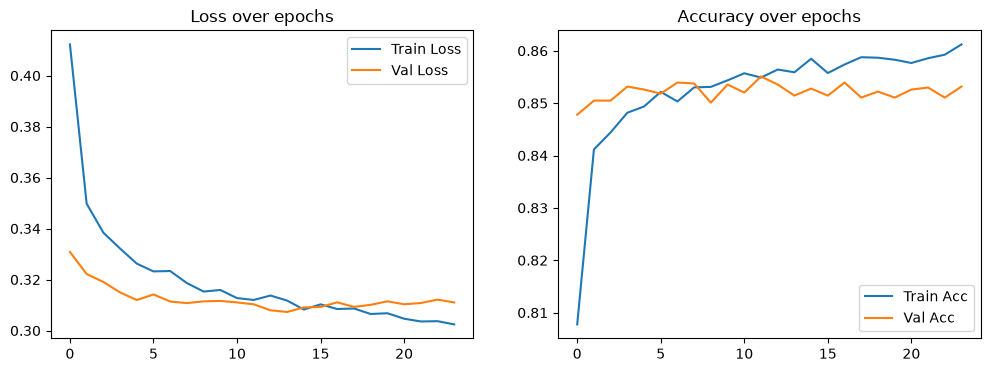

In [11]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss over epochs")

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title('Accuracy over epochs')
plt.show()

## 11. Предсказание для нового работника

In [12]:
# Создаем нового человека
new_person_data = {
    'age': [35],
    'workclass': ['Private'], 
    'education': ['Bachelors'],
    'education-num': [13],
    'marital-status': ['Married-civ-spouse'],
    'occupation': ['Tech-support'],
    'relationship': ['Husband'],
    'race': ['White'],
    'sex': ['Male'],
    'capital-gain': [0],
    'capital-loss': [0],
    'hours-per-week': [40],
    'native-country': ['United-States']
}
new_df = pd.DataFrame(new_person_data)

new_encoded = pd.get_dummies(new_df, drop_first=True)

new_encoded = new_encoded.reindex(columns=X_train.columns, fill_value=0)

new_scaled = scaler.transform(new_encoded)
prob = model.predict(new_scaled)
print(f"Вероятность, зарплаты > 50K: {prob[0][0]:.4f}")

if prob[0][0] > 0.5:
    print("Модель предсказывает: > 50K")
else:
    print("Модель предсказывает: <= 50K")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Вероятность, зарплаты > 50K: 0.0623
Модель предсказывает: <= 50K


Таким образом, модель правильно классифицирует около 86% объектов. При этом полнота для класса >50K составляет около 60%, то есть часть высокооплачиваемых работников модель пропускает - это связано с дисбалансом классов и может быть улучшено за счёт балансировки выборки, подбора порога классификации

Для нового работника с заданными характеристиками модель предсказала вероятность зарплаты >50K, равную 0,0623, и отнесла его к классу <=50K. Поставленная цель - изучить архитектуру и принцип работы нейронной сети на примере задачи бинарной классификации - была достигнута